# How much of a sender's same-model transfer survives into a different receiver, step by step?

**Statistics:** NOT run (built with --no-stats): no per-step paired Wilcoxon tests, "first step p<.05" is "—"; medians, surviving fractions and bootstrap bands are unchanged.

**Question.** For each sender A that has a same-model (A→A) per-checkpoint trajectory, how do its
cross-model A→B trajectories compare to A→A at every saved step, and which A→B vs A→A comparisons
cannot be made from the trajectories on disk?

**Value.** (p_student − p_control) / receiver prior, per run and saved step (absolute optimizer
steps), where p is test p_target and the control is the matched control run (same receiver,
the sender's base-model numbers, same cell) evaluated at the same step. A (run, step) with no
control at that step is dropped. Values can be ≤ 0 (0 = control level). Curves: per arm, median
over alive runs (anchored ΔCE dead cut at the endpoint, diverged excluded). **Surviving
fraction**: per step, over (teacher, cell) slots alive in both A→B and A→A, the median of
A→B value / A→A value, slots whose A→A value is ≤ 0 at that step dropped from that step; band =
95% teacher-cluster bootstrap (teachers resampled with replacement, 1,000 draws, seed 0). Paired
test per step: two-sided Wilcoxon signed-rank on A→A − A→B over the paired slots.

**Data.** Core-set arms (cat / pig / lion Pythia-160m orig / fs1–3 on core56, 41 saved steps
every 625 to 25,000; OLMo elephant on core35, 20 saves 625 … 12,500, each arm with its matched
base-numbers control read at the same 20 steps, so the OLMo cross arms use the same-step control
like the Pythia per-checkpoint arms; dog cross-size / cross-arch
arms on core30 / core35) and the Pythia-160m per-checkpoint arms on 10 stride-3 core30 cells,
keyed by animal: orig / fs1–3 diagonals and cross pairs for dog, cat, lion and pig, orig / ds1–3
and Rerun1234 / wc1 / wc2 pairs and diagonals, Rerun1234 ⇄ orig (dog), Rerun1234 ⇄ Modern1234 (dog), Modern1234 ⇄ orig on core30 (dog); each run read at
every step it saved (at least 625 … 3,750, 6,250, 12,500 and 25,000; every 625 steps where the
run's readout has them). An A→B arm is compared with the A→A diagonal of the same animal and
sender from the same data set; when an (animal, sender, receiver) is in both sets it is compared
once, from the per-checkpoint set (per-step controls). A comparison whose arms have no control
at any step is listed as not comparable ("no per-step control"). Sender and receiver must be the same model family and size (both
Pythia-160m variants or both OLMo-1B variants); cross-size / cross-architecture arms are listed as
not comparable ("different model size/architecture").

In [1]:
import time
import pandas as pd
from IPython.display import display
from subliminal_learning.analysis import trajectory_ab_vs_aa as ab
from subliminal_learning.analysis import trajectory_conditions as tc
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
STATS = False   # False: per-step paired Wilcoxon tests skipped (bands kept)
REPO, OUTPUT_ROOT = bootstrap(); FIG_DIR = REPO / "notebooks" / "figures"; set_plot_style()
FIG_DIR.mkdir(parents=True, exist_ok=True)
t0 = time.time()
CORE = tc.load_arms(tc.default_arms(REPO), OUTPUT_ROOT)
CKPT = tc.with_ep20_endpoints(tc.load_arms(tc.earlystop_arms(REPO), OUTPUT_ROOT), by_group=False)
SETS = {"core": CORE, "per-checkpoint": CKPT}
COMPS = ab.find_comparisons(SETS); CSTATS = ab.comparison_stats(SETS, COMPS, tests=STATS)
print(f"core: {len(CORE.arms)} arms, {len(CORE.runs):,} designed runs; per-checkpoint: {len(CKPT.arms)} arms, "
      f"{len(CKPT.runs):,} designed runs; {len(COMPS.comparisons)} comparable A→B arms, "
      f"{len(COMPS.not_comparable)} not comparable; {time.time() - t0:.0f} s")
for n in CKPT.notes:   # control endpoints without a Pile-probe label (kept unless labelled dead)
    if "unprobed" in n:
        print(n)

core: 116 arms, 47,860 designed runs; per-checkpoint: 190 arms, 11,110 designed runs; 87 comparable A→B arms, 4 not comparable; 821 s
orig→orig (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)
fs1→fs1 (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)
fs2→fs2 (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)
fs3→fs3 (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)
fs1→fs1 (cat) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)
orig→orig (lion) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label

In [2]:
# (0) Control coverage: per A→B arm and set, its matched control arm and the steps where that control has a
# point (control at the same step is required); then the not-comparable arms with their reason.
display(ab.control_inventory(SETS, COMPS).set_index(["set", "A→B"]))
NC = COMPS.not_comparable
display(NC.assign(**{"A→B": NC["A→B"].map(ab.display)}).drop(columns=["sender", "receiver"]).set_index("A→B"))

used  \
set            A→B                                      
core           orig→fs1 (dog)                   False   
               orig→fs2 (dog)                   False   
               orig→fs3 (dog)                   False   
               fs1→orig (dog)                   False   
               fs1→fs2 (dog)                    False   
...                                               ...   
per-checkpoint fs2→fs1 (pig) · per-checkpoint    True   
               fs2→fs3 (pig) · per-checkpoint    True   
               fs3→orig (pig) · per-checkpoint   True   
               fs3→fs1 (pig) · per-checkpoint    True   
               fs3→fs2 (pig) · per-checkpoint    True   

                                                                              control arm  \
set            A→B                                                                          
core           orig→fs1 (dog)                                                           —   
               orig→fs2 (dog)                                                           —   
               orig→fs3 (dog)                                                           —   
               fs1→orig (dog)                                                           —   
               fs1→fs2 (dog)                                                            —   
...                                                                                   ...   
per-checkpoint fs2→fs1 (pig) · per-checkpoint    fs2→fs1 (pig) · per-checkpoint · control   
               fs2→fs3 (pig) · per-checkpoint    fs2→fs3 (pig) · per-checkpoint · control   
               fs3→orig (pig) · per-checkpoint  fs3→orig (pig) · per-checkpoint · control   
               fs3→fs1 (pig) · per-checkpoint    fs3→fs1 (pig) · per-checkpoint · control   
               fs3→fs2 (pig) · per-checkpoint    fs3→fs2 (pig) · per-checkpoint · control   

                                                                   control steps  
set            A→B                                                                
core           orig→fs1 (dog)                                               none  
               orig→fs2 (dog)                                               none  
               orig→fs3 (dog)                                               none  
               fs1→orig (dog)                                               none  
               fs1→fs2 (dog)                                                none  
...                                                                          ...  
per-checkpoint fs2→fs1 (pig) · per-checkpoint   625…3,750, 6,250, 12,500, 25,000  
               fs2→fs3 (pig) · per-checkpoint   625…3,750, 6,250, 12,500, 25,000  
               fs3→orig (pig) · per-checkpoint  625…3,750, 6,250, 12,500, 25,000  
               fs3→fs1 (pig) · per-checkpoint   625…3,750, 6,250, 12,500, 25,000  
               fs3→fs2 (pig) · per-checkpoint   625…3,750, 6,250, 12,500, 25,000  

[151 rows x 3 columns]

,set,family,animal,reason
A→B,,,,
410m→160m (dog),core,Pythia,dog,different model size/architecture
410m-seed1→160m (dog),core,Pythia,dog,different model size/architecture
OLMo-dolma→160m (dog),core,OLMo,dog,different model size/architecture
160m→OLMo-dolma (dog),core,Pythia,dog,different model size/architecture


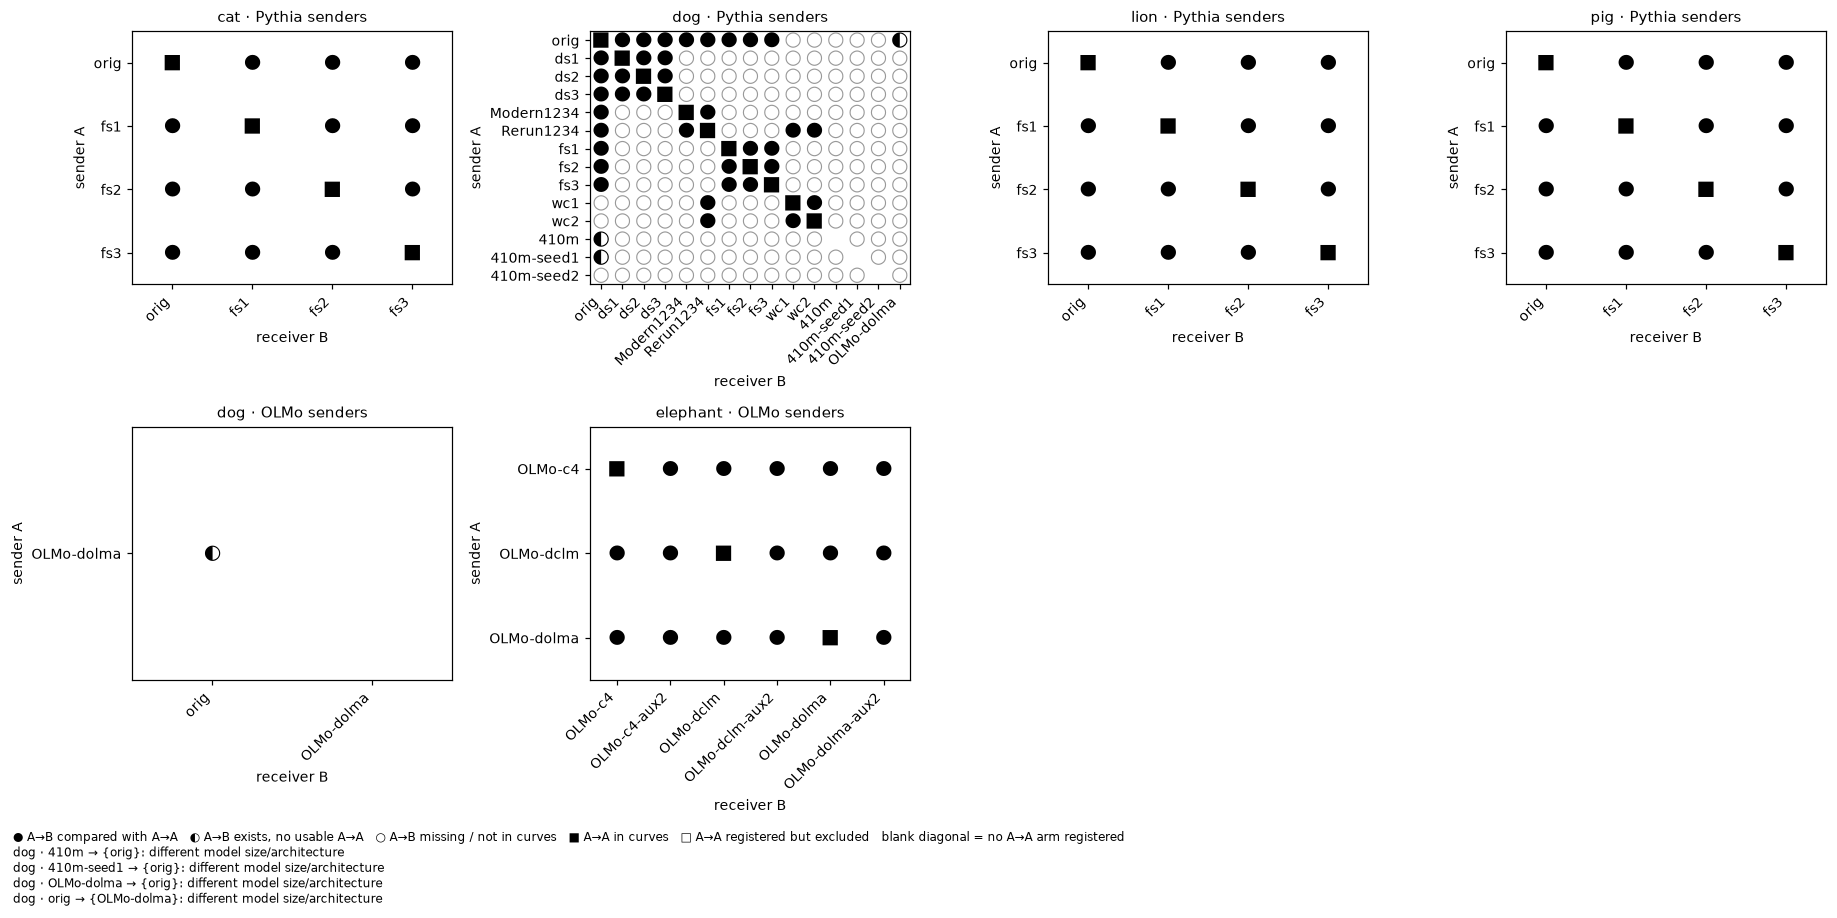

In [3]:
# (1) Coverage: rows = sender A, columns = receiver B, per sender family × animal. The footer gives,
# per not-comparable sender, the reason the A→A trajectory is unusable.
fig = ab.plot_coverage(SETS, COMPS)

**Curves: the dog figure and one "diff init, diff data order" figure with a block per animal.** The dog figure holds
four 2×2 blocks, one per group of related bases: diff init, diff data order (orig, fs1–fs3), same init,
diff data order (orig, ds1–ds3), diff init, same data order (Rerun1234, wc1, wc2), and Pythia-160M
re-pretrain (orig, Modern1234, Rerun1234). A
block has one panel per sender of the group: A→A in bold black, A→B only to receivers inside the
group, coloured by receiver: each receiver has one fixed colour in every panel of a block
(and the same four receiver colours in every animal's orig/fs1–fs3 block). A sender in several groups (dog orig) appears in each with that
group's receivers only. The second figure holds the diff init, diff data order block of each
animal (dog, cat, lion, pig), drawn exactly as in the dog figure; dog's block appears in both. The
third figure is the OLMo-1B elephant block: one panel per sender with an A→A diagonal (dolma, c4,
dclm), A→B to the six OLMo receivers (the three corpora and their seed-2 copies), same-step
control, 20 saves 625 … 12,500.
Block titles name the animal.

Each panel: median over alive runs of (p_student − p_control) / receiver prior, the control
evaluated at the same step, at the paired steps; A→A bold black with grey band, A→B coloured with
bands; bands = 95% teacher-cluster bootstrap of the per-step median (1,000 draws, seed 0). Symlog
y axis (linear between −1 and 1); dash-dot line at 0 = control level.

aa_ab_curves.csv: 1,242 rows


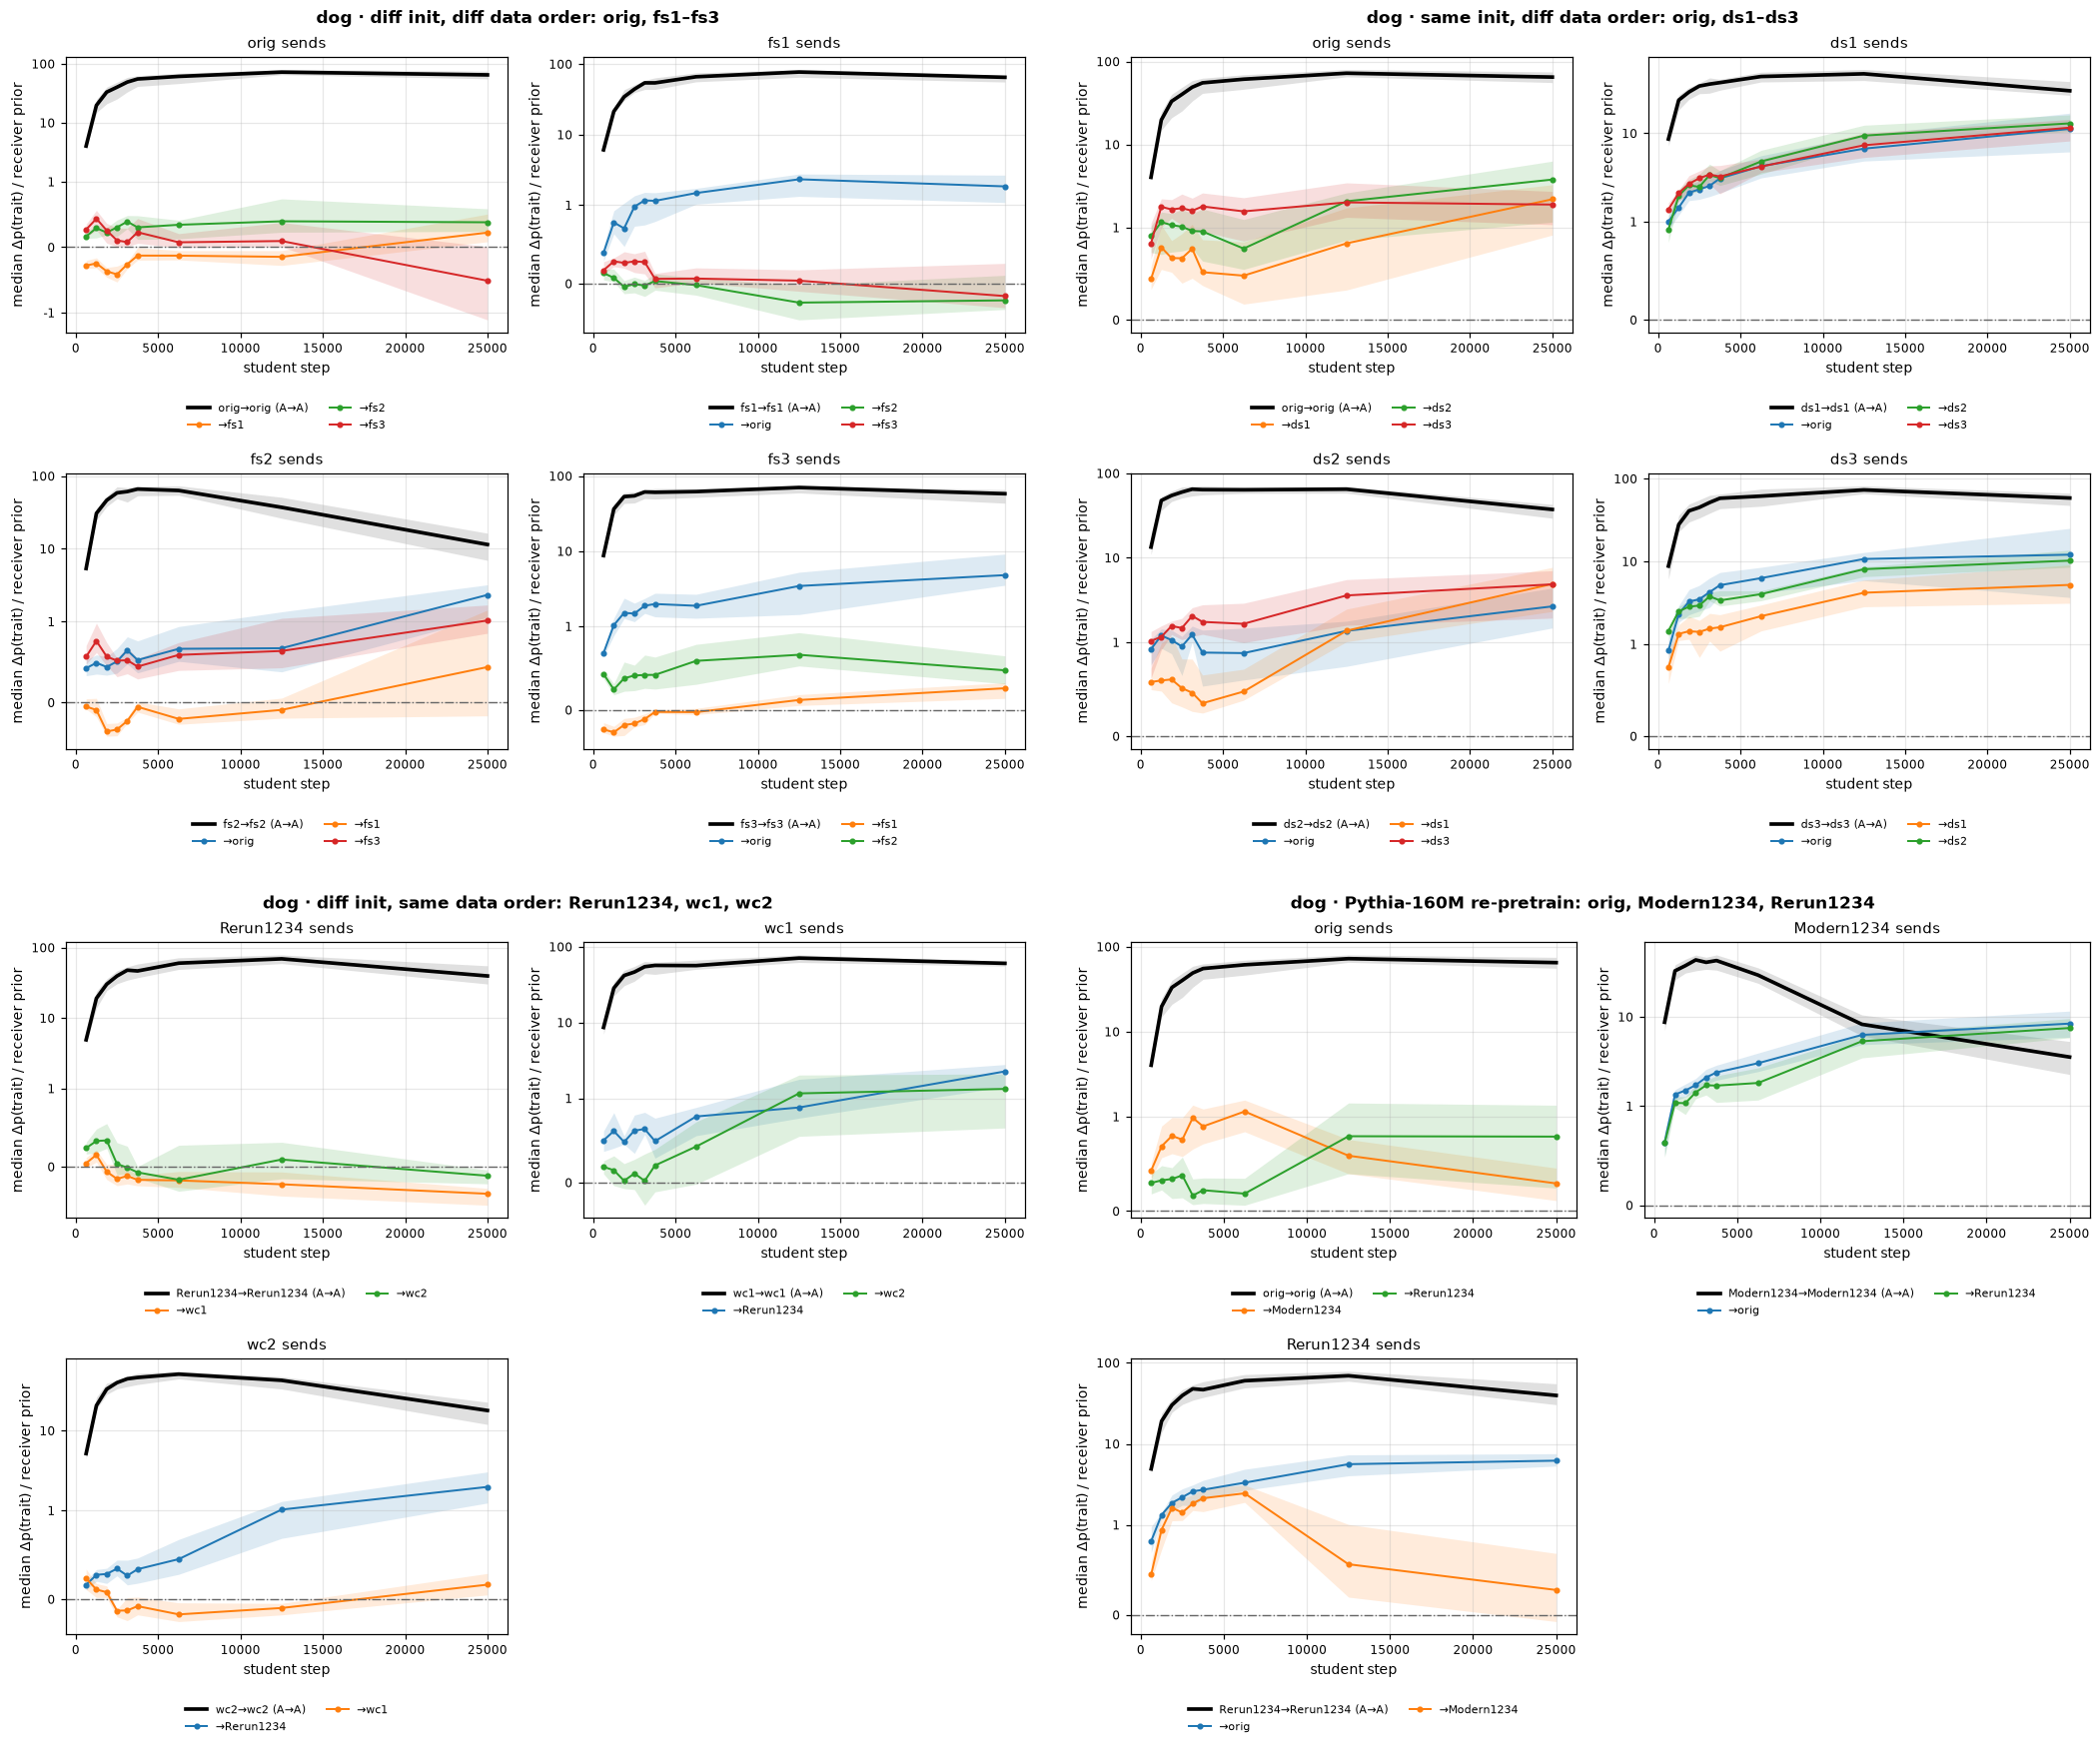

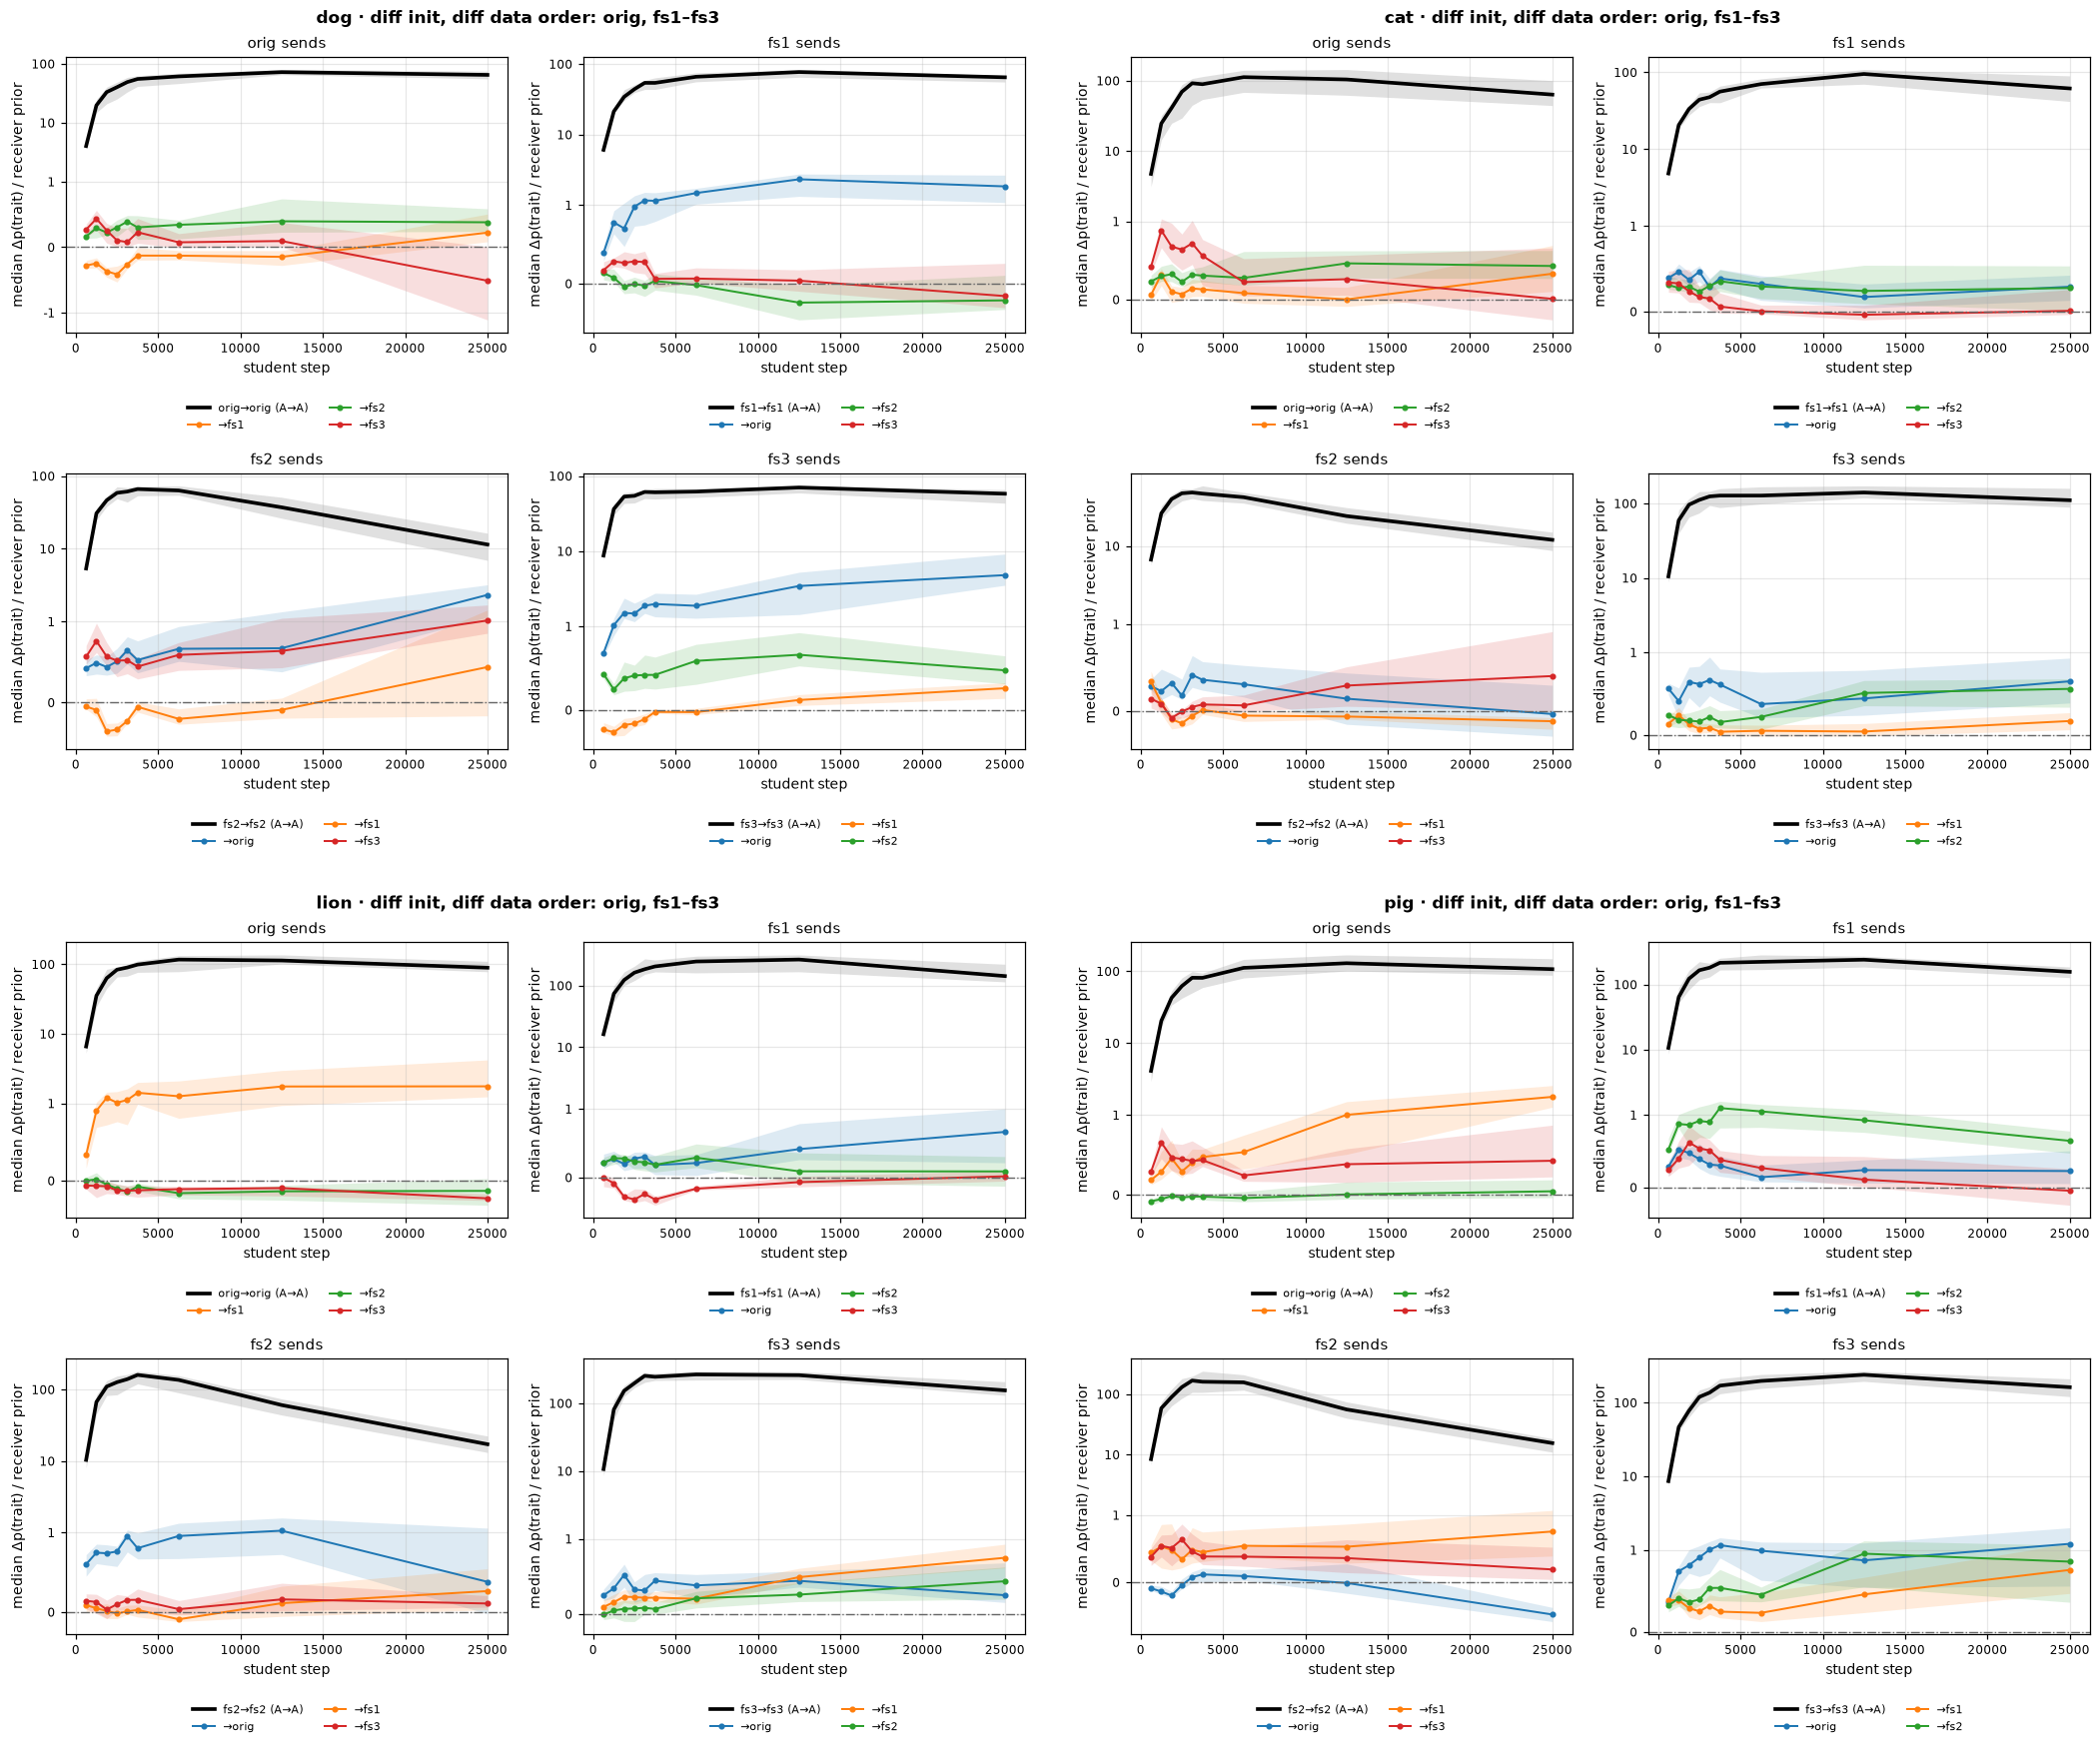

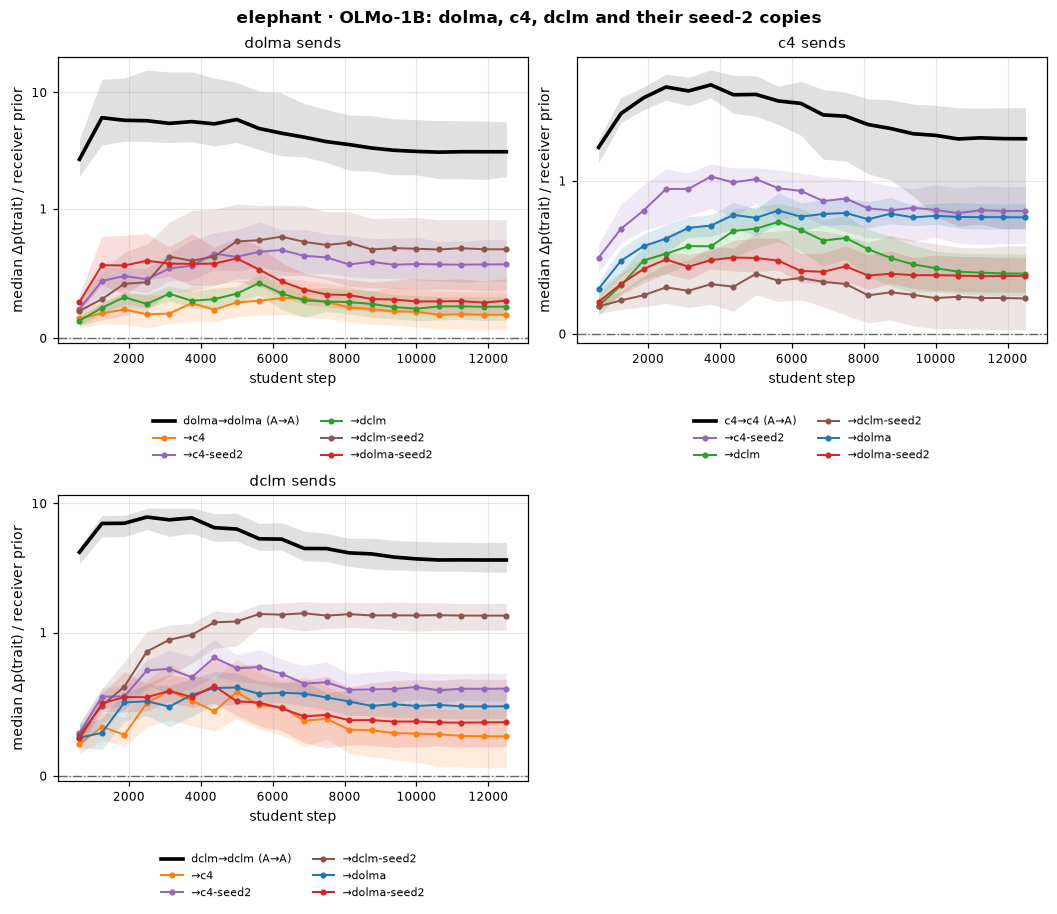

In [4]:
# (2) Curves: median (p_student − p_control) / prior over alive runs, control at the same step, at the paired steps; A→A bold black (grey band), A→B coloured by
# receiver; bands = 95% teacher-cluster bootstrap of the per-step median (1,000 draws, seed 0). Per-animal figure only for
# animals with more than one block (dog); then one diff init, diff data order figure with a block per animal; then the
# OLMo-1B elephant block (20 saves 625 … 12,500, same-step control). One fixed colour per receiver within a block.
import matplotlib.pyplot as plt
TRAJ_DIR = FIG_DIR / "asymmetry" / "trajectory" / "aa_ab"; TRAJ_DIR.mkdir(parents=True, exist_ok=True)
# Curve table behind the three figures; `aa_ab_curves.py` next to it redraws them from the CSV in seconds.
CURVES = ab.curve_table(CSTATS, COMPS); CURVES.to_csv(TRAJ_DIR / "aa_ab_curves.csv", index=False)
print(f"aa_ab_curves.csv: {len(CURVES):,} rows")
for animal, fig in ab.plot_curves(CURVES, min_blocks=2).items():   # dog only
    fig.savefig(TRAJ_DIR / "aa_ab_by_condition.png", dpi=130, bbox_inches="tight"); fig.savefig(TRAJ_DIR / "aa_ab_by_condition.pdf", bbox_inches="tight")
    plt.show()
fig = ab.plot_diffinit_diffdata_animals(CURVES)
fig.savefig(TRAJ_DIR / "aa_ab_by_trait.png", dpi=130, bbox_inches="tight"); fig.savefig(TRAJ_DIR / "aa_ab_by_trait.pdf", bbox_inches="tight")
plt.show()
fig = ab.plot_olmo_curves(CURVES)
fig.savefig(TRAJ_DIR / "aa_ab_olmo.png", dpi=130, bbox_inches="tight"); fig.savefig(TRAJ_DIR / "aa_ab_olmo.pdf", bbox_inches="tight")
plt.show()

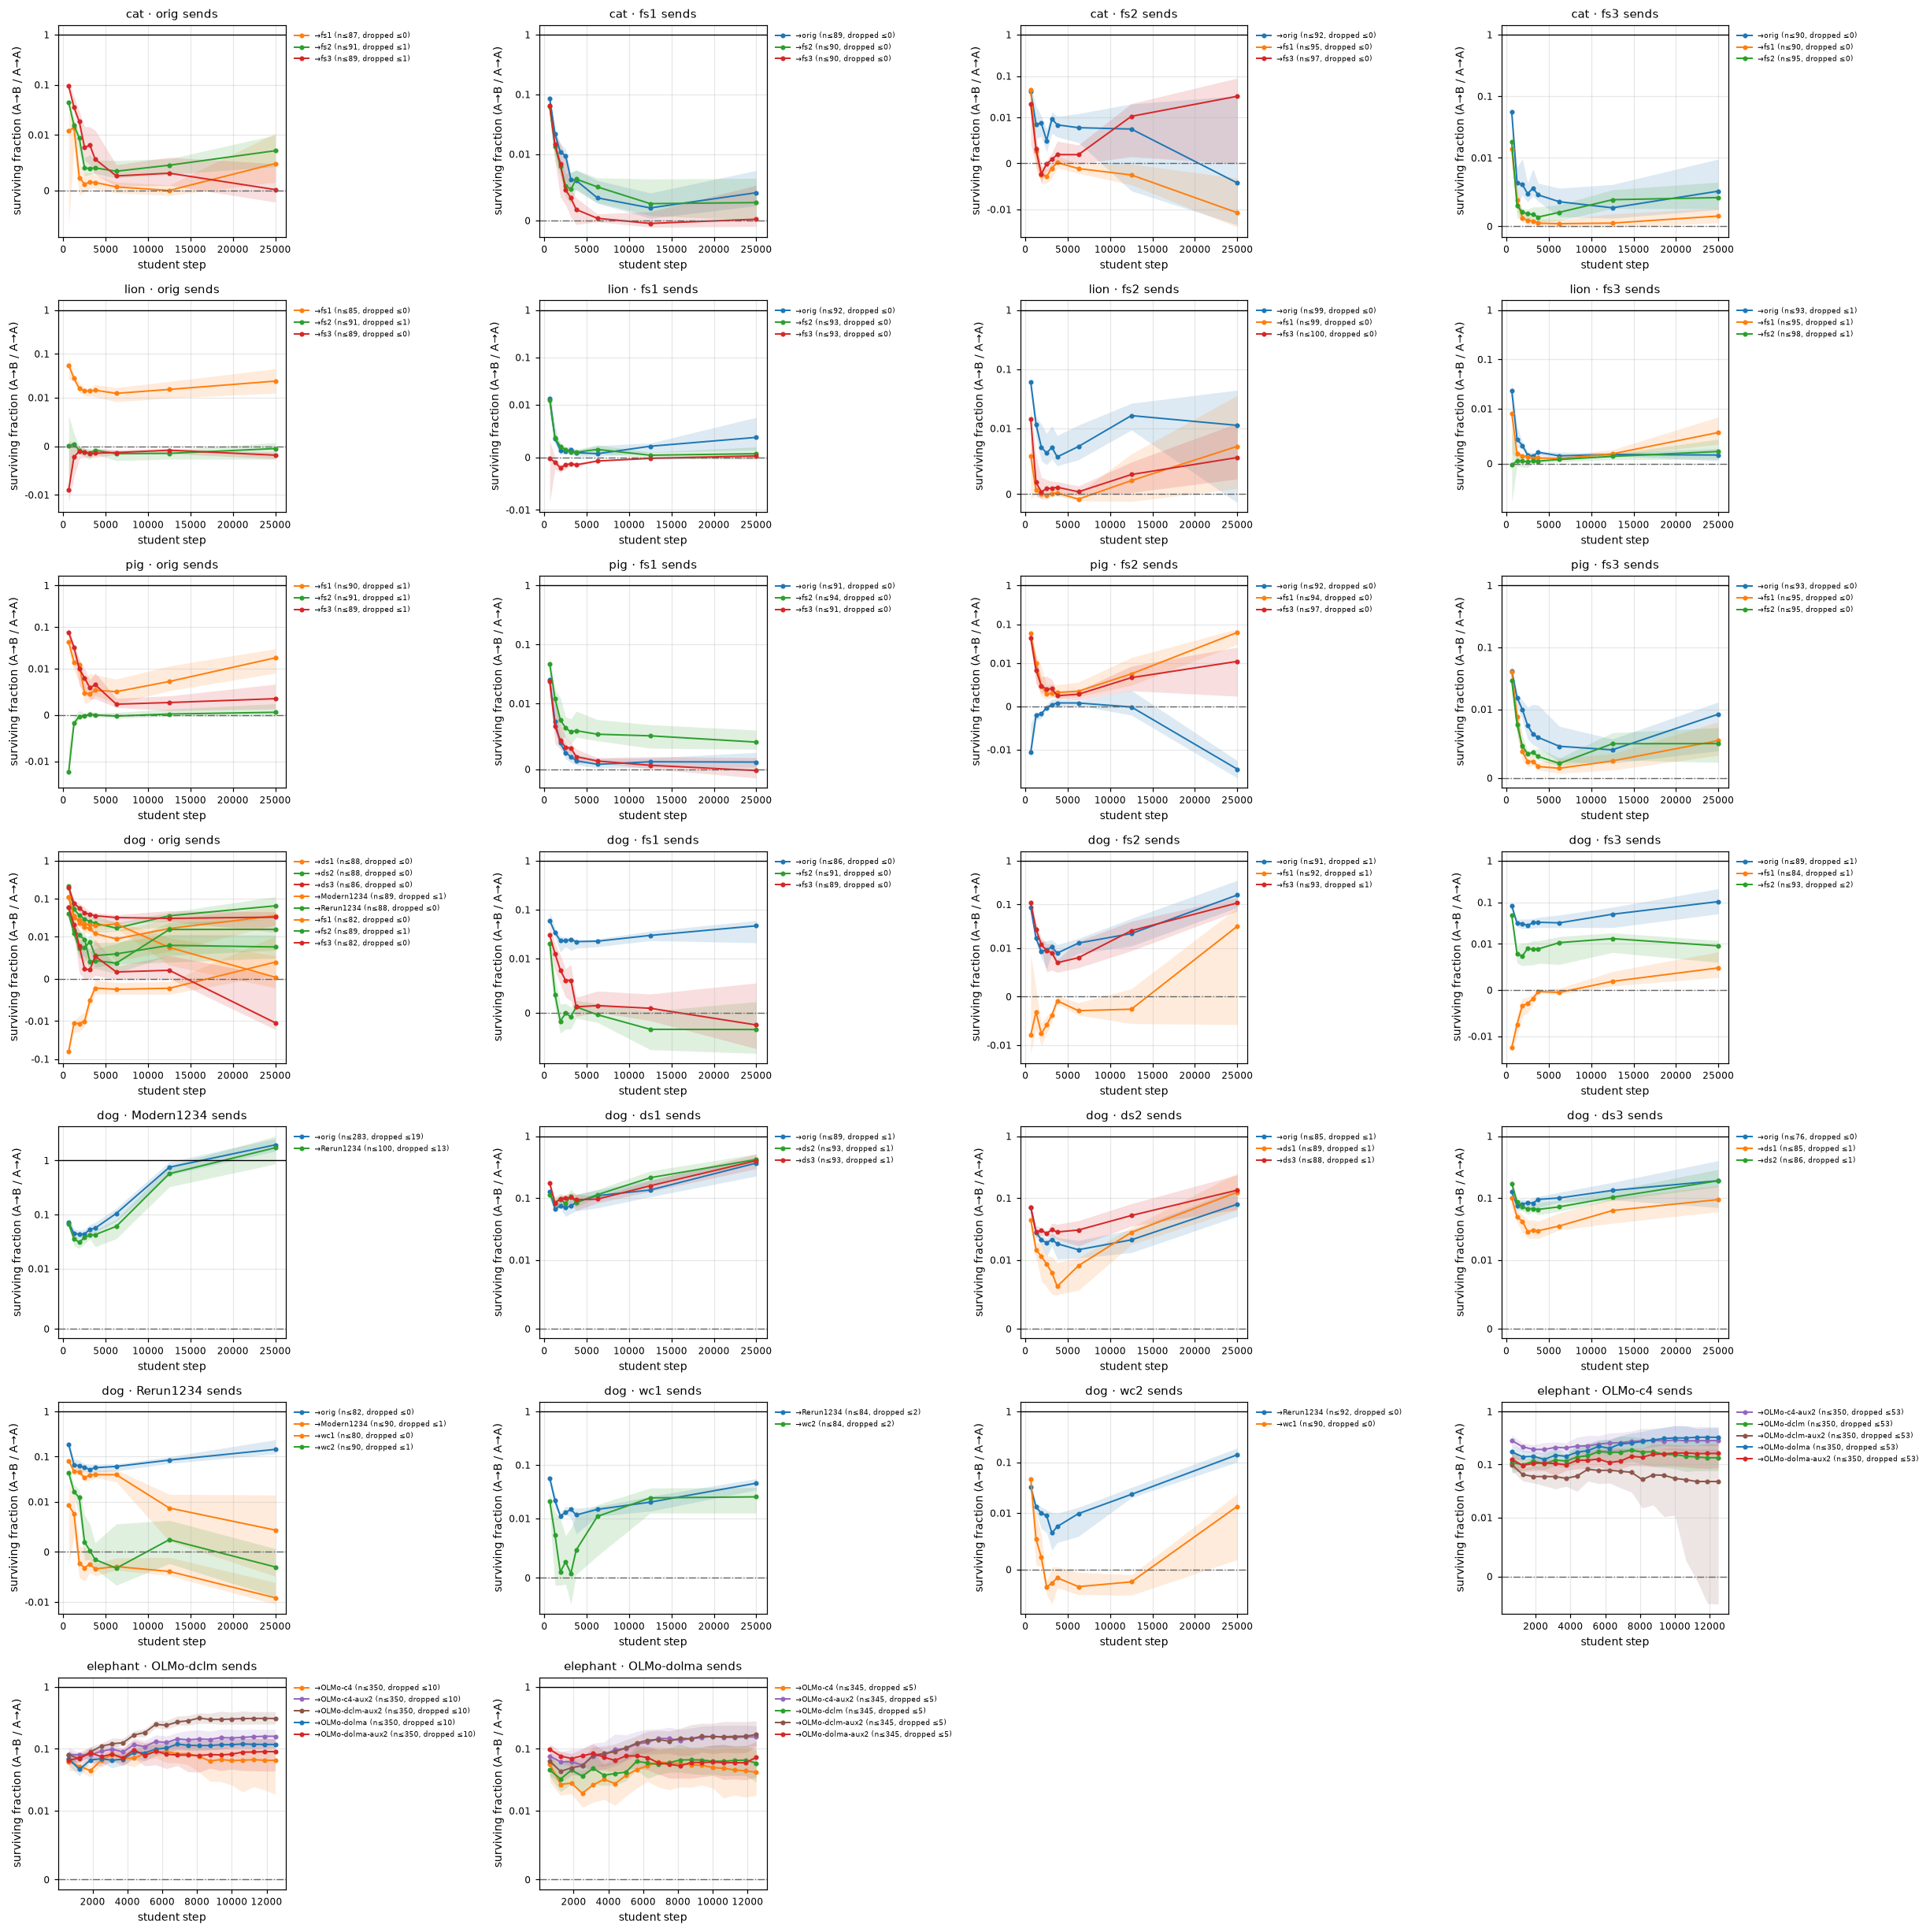

In [5]:
# (3) Surviving fraction: per step, median over paired slots of A→B / A→A, both (p_student − p_control) / prior
# with the control at the same step; slots with A→A ≤ 0 dropped from that step ("dropped ≤" in the legend = max
# per step); band = 95% teacher-cluster bootstrap; symlog y; line at 1 = A→B equals A→A.
fig = ab.plot_surviving(CSTATS, COMPS)

In [6]:
# (4) One row per comparison. Value = (p_student − p_control) / prior, control at the same step; peaks = max of the arm's median curve over
# the paired steps; surviving = median over paired slots of A→B / A→A at A→A's peak step and at the last paired
# step; first step p<.05 = first step whose paired Wilcoxon p (A→A − A→B) < .05.
SUMMARY = ab.summary_table(COMPS, CSTATS, tests=STATS)
display(SUMMARY.set_index("A→B").style.format(
    {"surviving @ A→A peak": "{:.3g}", "surviving @ last step": "{:.3g}"}, na_rep="—"))

,family,animal,n paired slots,steps,A→A peak (p−c)/prior (step),A→B peak (p−c)/prior (step),surviving @ A→A peak,surviving @ last step,first step p<.05,A→A > A→B every step
A→B,,,,,,,,,,
orig→fs1 (cat) · per-checkpoint,Pythia,cat,87,9,"112 (6,250)","0.331 (25,000)",0.000651,0.00486,—,True
orig→fs2 (cat) · per-checkpoint,Pythia,cat,91,9,"112 (6,250)","0.463 (12,500)",0.00347,0.00716,—,True
orig→fs3 (cat) · per-checkpoint,Pythia,cat,89,9,"112 (6,250)","0.885 (1,250)",0.00263,0.000172,—,True
fs1→orig (cat) · per-checkpoint,Pythia,cat,89,9,"95.2 (12,500)","0.467 (2,500)",0.0019,0.00419,—,True
fs1→fs2 (cat) · per-checkpoint,Pythia,cat,90,9,"95.2 (12,500)","0.355 (3,750)",0.00254,0.0027,—,True
fs1→fs3 (cat) · per-checkpoint,Pythia,cat,90,9,"95.2 (12,500)",0.34 (625),-0.000437,0.000198,—,True
fs2→orig (cat) · per-checkpoint,Pythia,cat,92,9,"48.5 (3,125)","0.416 (3,125)",0.00972,-0.00425,—,True
fs2→fs1 (cat) · per-checkpoint,Pythia,cat,95,9,"48.5 (3,125)",0.339 (625),-0.00103,-0.012,—,True
fs2→fs3 (cat) · per-checkpoint,Pythia,cat,97,9,"48.5 (3,125)","0.403 (25,000)",0.000877,0.0325,—,True


In [7]:
# (5) Conclusion, generated from the table above.
print("\n".join(ab.conclusion_lines(SUMMARY, COMPS, tests=STATS)))

87 A→B arms have a usable A→A trajectory; 4 do not (reasons in the not-comparable list).
At the sender's A→A peak step the median surviving fraction is 0.0072 (range -0.0039–0.21); at the last shared step 0.014 (range -0.032–1.9).
A→A exceeds A→B at every shared step in 85/87 comparisons.
OLMo: median surviving fraction at the last shared step 0.13 over 15 comparisons.
Pythia: median surviving fraction at the last shared step 0.0064 over 72 comparisons.
A→B at or above A→A at the last shared step: Modern1234→orig (dog) · per-checkpoint, Modern1234→Rerun1234 (dog).
